<img src="https://raw.githubusercontent.com/thegoodworks/dataworks-tb/main/assets/dataworks_banner.svg" alt="dataworks-banner" width="100%" />

# TB Starter · Vol. 01 — ✅ Solutions

**The worked answers. Try the [workbook](TB_starter.ipynb) first — struggling a little is where the learning happens!**

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/thegoodworks/dataworks-tb/blob/main/TB_starter_solutions.ipynb) &nbsp; [✏️ Back to the workbook](TB_starter.ipynb) &nbsp; [⭐ Star the repo](https://github.com/thegoodworks/dataworks-tb)

## 🔑 Answer key (spoilers below!)

| # | Question | Answer |
|---|----------|--------|
| 1 | Distinct values of Nigeria's `e_inc_100k`, 2000–2025 | **1** — it is 219 per 100,000 in *every* year |
| 2 | Nigeria's global rank by notifications (`c_newinc`), 2025 | **6th** of 184 reporting countries (455,258 cases) |
| 3 | Nigeria's share of WHO African Region incident cases, 2025 | **≈ 19.9%** (520,000 of 2,612,822) |
| 4 | USAID funding received, 2024 → 2025 | **$25.0M → $0.82M (−96.7%)** |
| 5 | Largest source of TB funding received, 2025 | **Global Fund** (≈ $51.3M) |
| 6 | National TB budget, 2025 → 2026 | **$405.1M → $202.8M (−50.0%)** |
| 7 | Biggest absolute budget cut, 2025 → 2026 | **C — programme costs for drug-susceptible TB** (−$118.6M) |
| 8 | Molecular rapid tests performed, 2024 → 2025 | **4,011,570 → 3,318,589 (−17.3%)** |
| 9 | Most common unfavourable outcome, latest cohort | **Lost to follow-up** (12,438 in the **2023** cohort — 2024 isn't reported yet) |
| 10 | Cohort year where "failed" > "died" | **2021** (5,646 vs 563 — almost certainly swapped) |
| B1 | First year treatment coverage ≥ 50% | **2022** (58%) |
| B2 | Under-5 household contacts started on TPT, 2024 → 2025 | **95,632 → 29,809 (−68.8%)** |
| B3 | Fastest notification growth since 2015 | **2021** (+50.8%) |
| B4 | Age–sex group with most notifications, 2025 | **Men aged 35–44** (55,151) |
| B5 | Funding received vs 2025 budget | **$328.0M gap** — only **19.0%** of the plan was funded |

---
## 🧰 Setup

Imports go at the top so the notebook can always be re-run from scratch. `pandas` is our table tool; `matplotlib` draws charts; `numpy` helps with numbers.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

%matplotlib inline
pd.set_option("display.max_columns", 30)
print("pandas", pd.__version__, "— ready to go ✅")

pandas 3.1.1 — ready to go ✅


A tiny warm-up so you've seen a *finished* gap-fill before the real ones. A pandas **Series** is just one column of numbers. `.nunique()` counts how many **distinct** values it holds:

In [2]:
s = pd.Series([10, 20, 20, 30])
s.nunique()   # 4 values in the column, but only 3 are distinct

3

---
## ⬇️ Step 1 — Get the data with `wget`

`wget` is a command-line downloader. In a notebook, a line starting with `!` runs in the **shell** instead of Python — that's how we mix the two.

**Why these URLs?** A normal GitHub link like `github.com/.../blob/.../file.csv` is a *web page about the file*. If you `wget` that, you download HTML, not data. The trick is **`raw.githubusercontent.com`**, which serves the file itself:

```
https://raw.githubusercontent.com/GTB-TME/gtbreport2026/main/gtb_database/<folder>/<file>.csv
```

We fetch **8 files** from [WHO's official repository](https://github.com/GTB-TME/gtbreport2026) into a `data/` folder. They're small (≈ 5 MB total) and re-running just re-downloads them — harmless.

| File | What's inside | Powers questions |
|------|---------------|------------------|
| `TB_dictionary…` | the official data dictionary: every column, defined | all of them 📖 |
| `TB_burden_estimates_countries…` | WHO's modelled estimates of TB cases & deaths | Q1, Q3 |
| `TB_notifications…` | cases countries actually reported | Q2 |
| `TB_budget…` | the money national TB programmes say they **need** | Q6, Q7 |
| `TB_expenditure_utilisation…` | the money they actually **received** and spent | Q4, Q5 |
| `TB_outcomes…` | what happened to patients after treatment | Q9, Q10 |
| `TB_laboratory_diagnostic_services…` | diagnostic tests performed | Q8 |
| `TB_contact_tpt…` | preventive treatment for contacts (incl. children) | bonus |

In [3]:
!mkdir -p data
!wget -nv -O data/TB_dictionary_2026-08-25.csv https://raw.githubusercontent.com/GTB-TME/gtbreport2026/main/gtb_database/dictionary/TB_dictionary_2026-08-25.csv
!wget -nv -O data/TB_burden_estimates_countries_2026-08-25.csv https://raw.githubusercontent.com/GTB-TME/gtbreport2026/main/gtb_database/estimates/TB_burden_estimates_countries_2026-08-25.csv
!wget -nv -O data/TB_notifications_2026-08-25.csv https://raw.githubusercontent.com/GTB-TME/gtbreport2026/main/gtb_database/reported_data/TB_notifications_2026-08-25.csv

2026-11-16 16:58:56 URL:https://raw.githubusercontent.com/GTB-TME/gtbreport2026/main/gtb_database/dictionary/TB_dictionary_2026-08-25.csv [128885/128885] -> "data/TB_dictionary_2026-08-25.csv" [1]


2026-11-16 16:58:56 URL:https://raw.githubusercontent.com/GTB-TME/gtbreport2026/main/gtb_database/estimates/TB_burden_estimates_countries_2026-08-25.csv [1074519/1074519] -> "data/TB_burden_estimates_countries_2026-08-25.csv" [1]


2026-11-16 16:58:57 URL:https://raw.githubusercontent.com/GTB-TME/gtbreport2026/main/gtb_database/reported_data/TB_notifications_2026-08-25.csv [2878117/2878117] -> "data/TB_notifications_2026-08-25.csv" [1]


In [4]:
!wget -nv -O data/TB_budget_2026-08-25.csv https://raw.githubusercontent.com/GTB-TME/gtbreport2026/main/gtb_database/reported_data/TB_budget_2026-08-25.csv
!wget -nv -O data/TB_expenditure_utilisation_2026-08-25.csv https://raw.githubusercontent.com/GTB-TME/gtbreport2026/main/gtb_database/reported_data/TB_expenditure_utilisation_2026-08-25.csv

2026-11-16 16:58:57 URL:https://raw.githubusercontent.com/GTB-TME/gtbreport2026/main/gtb_database/reported_data/TB_budget_2026-08-25.csv [296413/296413] -> "data/TB_budget_2026-08-25.csv" [1]


2026-11-16 16:58:57 URL:https://raw.githubusercontent.com/GTB-TME/gtbreport2026/main/gtb_database/reported_data/TB_expenditure_utilisation_2026-08-25.csv [300718/300718] -> "data/TB_expenditure_utilisation_2026-08-25.csv" [1]


In [5]:
!wget -nv -O data/TB_outcomes_2026-08-25.csv https://raw.githubusercontent.com/GTB-TME/gtbreport2026/main/gtb_database/reported_data/TB_outcomes_2026-08-25.csv
!wget -nv -O data/TB_laboratory_diagnostic_services_2026-08-25.csv https://raw.githubusercontent.com/GTB-TME/gtbreport2026/main/gtb_database/reported_data/TB_laboratory_diagnostic_services_2026-08-25.csv
!wget -nv -O data/TB_contact_tpt_2026-08-25.csv https://raw.githubusercontent.com/GTB-TME/gtbreport2026/main/gtb_database/reported_data/TB_contact_tpt_2026-08-25.csv

2026-11-16 16:58:57 URL:https://raw.githubusercontent.com/GTB-TME/gtbreport2026/main/gtb_database/reported_data/TB_outcomes_2026-08-25.csv [980542/980542] -> "data/TB_outcomes_2026-08-25.csv" [1]


2026-11-16 16:58:57 URL:https://raw.githubusercontent.com/GTB-TME/gtbreport2026/main/gtb_database/reported_data/TB_laboratory_diagnostic_services_2026-08-25.csv [431189/431189] -> "data/TB_laboratory_diagnostic_services_2026-08-25.csv" [1]


2026-11-16 16:58:57 URL:https://raw.githubusercontent.com/GTB-TME/gtbreport2026/main/gtb_database/reported_data/TB_contact_tpt_2026-08-25.csv [177936/177936] -> "data/TB_contact_tpt_2026-08-25.csv" [1]


In [6]:
!ls -lh data

total 6.0M
-rw-r--r-- 1 root root 290K Nov 16 16:58 TB_budget_2026-08-25.csv
-rw-r--r-- 1 root root 1.1M Nov 16 16:58 TB_burden_estimates_countries_2026-08-25.csv
-rw-r--r-- 1 root root 174K Nov 16 16:58 TB_contact_tpt_2026-08-25.csv
-rw-r--r-- 1 root root 126K Nov 16 16:58 TB_dictionary_2026-08-25.csv
-rw-r--r-- 1 root root 294K Nov 16 16:58 TB_expenditure_utilisation_2026-08-25.csv
-rw-r--r-- 1 root root 422K Nov 16 16:58 TB_laboratory_diagnostic_services_2026-08-25.csv
-rw-r--r-- 1 root root 2.8M Nov 16 16:58 TB_notifications_2026-08-25.csv
-rw-r--r-- 1 root root 958K Nov 16 16:58 TB_outcomes_2026-08-25.csv


---
## 📖 Step 2 — Meet the data dictionary

Never analyse columns you don't understand. WHO ships a **dictionary**: 740 rows, one per column, with official definitions. Load it first.

> ⚠️ **Real-world war story:** when we first built this notebook, `pd.read_csv(...)` crashed with `UnicodeDecodeError: 'utf-8' codec can't decode byte 0x91`. The file contains Windows-style "smart quotes", so it isn't UTF-8. The fix is `encoding="latin-1"`, which can read any byte. You *will* meet this error in your own work — now you know the fix.

In [7]:
dic = pd.read_csv("data/TB_dictionary_2026-08-25.csv", encoding="latin-1")
print(dic.shape)   # (rows, columns)
dic.head()

(740, 5)


,dataset,variable_name,type,code_list,definition
0,Budget,tx_dstb,numeric,NaN,Number of patients expected to start drug-susc...
1,Budget,budget_cpp_dstb,numeric,NaN,Average cost of drugs budgeted per patient for...
2,Budget,tx_mdr,numeric,NaN,Number of patients expected to start MDR-TB tr...
3,Budget,budget_cpp_mdr,numeric,NaN,Average cost of drugs budgeted per patient for...
4,Budget,tx_xdr,numeric,NaN,Number of patients expected to start pre-XDR/X...


Let's build a tiny tool we'll reuse all notebook: `lookup("column_name")` prints the official definition. (A **function** is a reusable recipe — `def` defines it once, then we call it by name.)

In [8]:
def lookup(name):
    """Look up a column in the WHO data dictionary."""
    hit = dic[dic["variable_name"] == name]
    if hit.empty:
        return f"No column called '{name}' — check the spelling?"
    return hit[["dataset", "variable_name", "definition"]]

lookup("e_inc_100k")

,dataset,variable_name,definition
38,Burden estimates,e_inc_100k,Estimated incidence (all forms) per 100 000 po...


### 🏷️ Crack the column-name code

WHO column names look cryptic, but they're built from prefixes. Learn these seven and most of the database reads like English:

| Prefix | Meaning | Example |
|--------|---------|---------|
| `e_` | WHO **estimate** (modelled, not directly counted) | `e_inc_num` = estimated incident cases |
| `c_` | **count** reported by the country | `c_newinc` = notified new + relapse cases |
| `budget_` | money **required** (the plan) | `budget_tot` = total budget needed |
| `rcvd_` | money **received** (what actually arrived) | `rcvd_tot_usaid` = funding received from USAID |
| `exp_` | money **spent** | `exp_tot` = total expenditure |
| `newrel_` | outcomes for the **new + relapse** treatment cohort | `newrel_died` = died during treatment |
| `m_wrd_` | **m**olecular **W**HO-**r**ecommended rapid **d**iagnostics | `m_wrd_tests_performed` |

### ⭐ The columns that matter for our 10 questions

| Column | File | Plain English | Units |
|--------|------|---------------|-------|
| `country`, `year`, `g_whoregion` | all | who, when, and which WHO region (`AFR` = African Region) | — |
| `e_pop_num` | estimates | estimated population | people |
| `e_inc_100k` | estimates | estimated new TB cases **per 100,000 people** per year | rate |
| `e_inc_num` | estimates | estimated new TB cases per year | cases |
| `c_cdr` | estimates | treatment coverage — % of estimated cases that get diagnosed & notified | % |
| `c_newinc` | notifications | new + relapse cases actually notified | cases |
| `budget_tot` | budget | total national TB budget required | US$ |
| `budget_lab` / `budget_staff` / `budget_prog` / `budget_mdrmgt` | budget | laboratory / staff / drug-susceptible TB programme / MDR-TB programme budget lines | US$ |
| `rcvd_tot` | funding | total funding received | US$ |
| `rcvd_tot_domestic` / `_gf` / `_usaid` / `_grnt` | funding | received from government / Global Fund / USAID / other sources | US$ |
| `m_wrd_tests_performed` | laboratory | molecular rapid diagnostic tests performed | tests |
| `newrel_coh` / `_succ` / `_died` / `_fail` / `_lost` / `_neval` | outcomes | cohort size / treatment success / died / failed / lost to follow-up / not evaluated | people |
| `newinc_con04_prevtx` | contacts & TPT | under-5 household contacts started on preventive treatment | children |

Keep this table handy — every question below tells you which rows of it you need.

---
## 🐼 Step 3 — Your first table (and the 6 words you need)

| Word | Meaning |
|------|---------|
| **DataFrame** | a table of rows × columns, like a spreadsheet |
| **Series** | one column of a DataFrame |
| **mask** | a True/False test that keeps matching rows: `df[df["year"] == 2025]` |
| **method** | a verb you attach to data: `.sum()`, `.nunique()`, `.sort_values()` |
| **NaN** | "not a number" — an empty cell. Real data is full of them |
| **index** | the row labels; by default 0, 1, 2, … (pandas counts from **zero**!) |

Load the **burden estimates** — WHO's modelled picture of TB in every country, 2000–2025:

In [9]:
est = pd.read_csv("data/TB_burden_estimates_countries_2026-08-25.csv")
print(est.shape)
est.head(3)

(5452, 50)


,country,iso2,iso3,iso_numeric,g_whoregion,year,e_pop_num,e_inc_100k,e_inc_100k_lo,e_inc_100k_hi,e_inc_num,e_inc_num_lo,e_inc_num_hi,e_tbhiv_prct,e_tbhiv_prct_lo,...,e_mort_100k_lo,e_mort_100k_hi,e_mort_num,e_mort_num_lo,e_mort_num_hi,cfr,cfr_lo,cfr_hi,c_newinc_100k,c_cdr,c_cdr_lo,c_cdr_hi,cfr_pct,cfr_pct_lo,cfr_pct_hi
0,Afghanistan,AF,AFG,4,EMR,2000,20130327.0,148.0,65.0,2310.0,30000.0,13000.0,464000.0,0.017,NaN,...,32.0,71.0,10000.0,6300.0,14000.0,0.34,0.19,0.52,35.0,24.0,1.5,54.0,34.0,19.0,52.0
1,Afghanistan,AF,AFG,4,EMR,2001,20284307.0,153.0,71.0,1650.0,31000.0,14000.0,334000.0,0.015,NaN,...,30.0,65.0,9300.0,6100.0,13000.0,0.30,0.18,0.45,50.0,33.0,3.0,70.0,30.0,18.0,45.0
2,Afghanistan,AF,AFG,4,EMR,2002,21378117.0,158.0,78.0,1240.0,34000.0,17000.0,265000.0,0.014,NaN,...,28.0,59.0,9000.0,6000.0,13000.0,0.27,0.16,0.40,65.0,41.0,5.2,83.0,27.0,16.0,40.0


5,452 rows × 50 columns — every country × every year. We only care about **Nigeria**, so let's filter. `est["country"] == "Nigeria"` produces a True/False mask; putting it inside `est[...]` keeps only the True rows. We'll wrap that in a helper so every file gets the same treatment:

In [10]:
def nga(df):
    """Keep only Nigeria rows — our focus country."""
    return df[df["country"] == "Nigeria"]

nga_est = nga(est)
print("Nigeria rows:", len(nga_est), "| years:", nga_est["year"].min(), "–", nga_est["year"].max())
nga_est[["year", "e_pop_num", "e_inc_100k", "e_inc_num", "c_cdr"]].tail(3)

Nigeria rows: 26 | years: 2000 – 2025


,year,e_pop_num,e_inc_100k,e_inc_num,c_cdr
3550,2023,227882945.0,219.0,499000.0,74.0
3551,2024,232679477.5,219.0,510000.0,79.0
3552,2025,237527781.5,219.0,520000.0,88.0


In [11]:
g = nga_est[nga_est["year"] == 2025].iloc[0]   # .iloc[0] = the first (only) matching row
print(f"Nigeria at a glance, 2025")
print(f"  Population:            {g.e_pop_num:,.0f}")
print(f"  Estimated TB incidence: {g.e_inc_100k:.0f} per 100,000 people")
print(f"  Estimated new cases:    {g.e_inc_num:,.0f}")
print(f"  Treatment coverage:     {g.c_cdr:.0f}% of estimated cases")

Nigeria at a glance, 2025
  Population:            237,527,782
  Estimated TB incidence: 219 per 100,000 people
  Estimated new cases:    520,000
  Treatment coverage:     88% of estimated cases


---
# Part 1 · How big is the problem? 🦠

## Q1 · How many *distinct* values does Nigeria's incidence rate (`e_inc_100k`) take across 2000–2025?

**Why ask this?** The incidence rate is the heartbeat of an epidemic: new cases per 100,000 people per year. If it barely moves across 26 years, that tells you something profound about the epidemic — *or* about how the estimate is made. Counting distinct values is a classic first sniff-test of any time series.

**🧭 Think it through**
1. Keep only Nigeria rows (already done: `nga_est`).
2. Keep years 2000–2025 with two conditions joined by `&` (each condition needs its own parentheses).
3. Ask the `e_inc_100k` column: *how many different values do you hold?* — not *how many rows*.

**📖 Column spotlight** — `e_inc_100k`: *"Estimated incidence (all forms) per 100 000 population"* (WHO dictionary).

> 💡 **Hint:** "how many rows?" and "how many different values?" are different questions, answered by different methods. One of the options counts rows; another counts uniques.

In [12]:
# Look at the raw material first — always eyeball before you compute
nga_est[["year", "e_inc_100k", "e_inc_num"]].head(8)

,year,e_inc_100k,e_inc_num
3527,2000,219.0,277000.0
3528,2001,219.0,284000.0
3529,2002,219.0,292000.0
3530,2003,219.0,301000.0
3531,2004,219.0,309000.0
3532,2005,219.0,318000.0
3533,2006,219.0,327000.0
3534,2007,219.0,336000.0


**✅ The gap:** `.nunique()` — option **B**. It counts *distinct* values, which is exactly the question. `.count()` would return 26 (the number of rows), `.sum()` would add the rates (meaningless), `.size` also counts rows.

In [13]:
# Q1 — solution: B) .nunique()
nga_2000_2025 = nga_est[(nga_est["year"] >= 2000) & (nga_est["year"] <= 2025)]
answer_q1 = nga_2000_2025["e_inc_100k"].nunique()
print("Distinct incidence-rate values, 2000–2025:", answer_q1)

Distinct incidence-rate values, 2000–2025: 1


**🤯 What this means:** the answer is **1**. WHO's estimate of Nigeria's incidence *rate* has been **219 per 100,000 in every single year since 2000**. Nigeria has never run a national TB prevalence survey, so WHO has no new measurement to update the rate — it carries the same modelled value forward. Meanwhile `e_inc_num` (the *number* of cases) still grows, because the population grows. **Lesson: an estimate that never changes is a flag about the evidence base, not proof that the epidemic is static.**

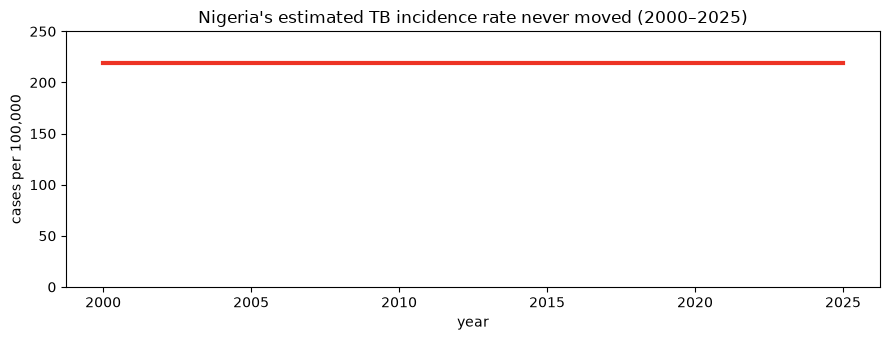

In [14]:
# The flat line that launched a thousand questions
fig, ax = plt.subplots(figsize=(9, 3.5))
ax.plot(nga_2000_2025["year"], nga_2000_2025["e_inc_100k"], color="#ED3324", lw=3)
ax.set_ylim(0, 250)
ax.set_title("Nigeria's estimated TB incidence rate never moved (2000–2025)")
ax.set_ylabel("cases per 100,000")
ax.set_xlabel("year")
plt.tight_layout(); plt.show()

## Q2 · Ranked by cases notified in 2025 (`c_newinc`), where does Nigeria sit globally?

**Why ask this?** Notifications are cases the health system actually *found and reported* — the operational scoreboard. League tables decide where global attention (and money) goes.

**🧭 Think it through**
1. Switch files: notifications, not estimates. Keep year 2025 only.
2. Keep just `country` and `c_newinc`, and drop rows where `c_newinc` is empty (`.dropna()`) — countries that didn't report can't be ranked.
3. Sort **biggest first**, then reset the index so row numbers become 0, 1, 2, …
4. Find Nigeria's row number… and remember pandas counts from **zero**, humans from **one**.

**📖 Column spotlight** — `c_newinc`: *"Total of new and recurrent (relapse) cases and cases with unknown previous TB treatment history."*

> 💡 **Hint:** `ascending=False` means biggest at the top. And if Nigeria lands at index 5, a human would call that position… ?

In [15]:
noti = pd.read_csv("data/TB_notifications_2026-08-25.csv")
print(noti.shape)
noti[noti["year"] == 2025][["country", "c_newinc"]].head()

(9337, 221)


,country,c_newinc
40,Afghanistan,49925.0
84,Albania,241.0
129,Algeria,18500.0
174,American Samoa,NaN
210,Andorra,0.0


**✅ The gaps:** `ascending=False` (**B**) puts the biggest notifier on top; `+ 1` (**B**) converts the zero-based index into a human rank. Index 5 → rank 6.

In [16]:
# Q2 — solution: ascending=False, then + 1
top_2025 = noti[noti["year"] == 2025][["country", "c_newinc"]].dropna()
ranked = top_2025.sort_values("c_newinc", ascending=False).reset_index(drop=True)
nigeria_rank = ranked.index[ranked["country"] == "Nigeria"][0] + 1
print(f"Nigeria: rank {nigeria_rank} of {len(ranked)} reporting countries")
ranked.head(8)

Nigeria: rank 6 of 184 reporting countries


,country,c_newinc
0,India,2531604.0
1,Indonesia,849740.0
2,Philippines,535254.0
3,China,522745.0
4,Pakistan,483649.0
5,Nigeria,455258.0
6,Bangladesh,323584.0
7,Democratic Republic of the Congo,283406.0


**Why it works:** `.dropna()` removes non-reporters so they don't distort the league table; `.reset_index(drop=True)` turns the sorted order into fresh 0-based row numbers, so *position = rank − 1*. **Nigeria is 6th of 184** with 455,258 notified cases — behind India, Indonesia, Philippines, China and Pakistan. Note the gap to #1: India notifies more than 5× as many cases.

## Q3 · What share of the WHO African Region's estimated incident cases in 2025 is Nigeria's?

**Why ask this?** "Nigeria has 520,000 cases" is a number; "Nigeria has *one in five* of the region's cases" is a **story**. Shares turn counts into context — the bread and butter of analysis.

**🧭 Think it through**
1. Keep year 2025 **and** the WHO African Region. Region is stored as a code in `g_whoregion` — what's the right code? (The explorer cell below shows them all.)
2. Pull Nigeria's `e_inc_num` out of that slice.
3. Add up `e_inc_num` for the whole region.
4. Share = part ÷ whole × 100. Never the other way round!

**📖 Column spotlight** — `e_inc_num`: *"Estimated number of incident cases (all forms)"*; `g_whoregion`: *"WHO region"*.

> 💡 **Hint:** WHO region codes are three letters. Africa is not spelled out in full in the data. And a share above 100% means you divided upside down.

In [17]:
# What region codes exist, and how many countries in each (2025)?
est[est["year"] == 2025]["g_whoregion"].value_counts()

g_whoregion
EUR    54
AFR    47
AMR    45
WPR    37
EMR    22
SEA    10
Name: count, dtype: int64

**✅ The gaps:** `"AFR"` (**B**) is the WHO code for the African Region (you saw it in `value_counts()`), and `.sum()` (**C**) adds the 47 countries' estimated cases into one regional total.

In [18]:
# Q3 — solution: "AFR" and .sum()
afr_2025 = est[(est["year"] == 2025) & (est["g_whoregion"] == "AFR")]
nigeria_cases = afr_2025.loc[afr_2025["country"] == "Nigeria", "e_inc_num"].iloc[0]
afr_cases = afr_2025["e_inc_num"].sum()
share_pct = 100 * nigeria_cases / afr_cases
print(f"Nigeria: {nigeria_cases:,.0f} of {afr_cases:,.0f} regional cases = {share_pct:.1f}%")

Nigeria: 520,000 of 2,612,822 regional cases = 19.9%


**Why it works:** two masks joined with `&` carve out exactly *AFR × 2025*; `.loc[mask, "e_inc_num"].iloc[0]` plucks Nigeria's single value; `.sum()` aggregates the region. **Nigeria ≈ 19.9%** — about **1 in 5** of all estimated TB cases in the WHO African Region (520,000 of 2,612,822). One country, one fifth of a continent's burden: that's why donors watch Nigeria so closely. (Estimates are rounded, so treat the decimal as approximate.)

---
# Part 2 · Follow the money 💰

TB programmes run on budgets (the plan) and funding received (the reality). In 2025 the global aid architecture shifted violently — and Nigeria's numbers show it. Load the two money files:

In [19]:
bud  = pd.read_csv("data/TB_budget_2026-08-25.csv")                  # money REQUIRED (the plan)
fund = pd.read_csv("data/TB_expenditure_utilisation_2026-08-25.csv") # money RECEIVED & spent (reality)
print("budget:", bud.shape, "| funding:", fund.shape)

budget: (1909, 43) | funding: (1926, 46)


## Q4 · How did USAID funding received change from 2024 to 2025?

**Why ask this?** USAID was for decades one of the largest bilateral funders of TB worldwide. In 2025 it was dismantled. What does that look like in one country's ledger? This is history you can *compute*.

**🧭 Think it through**
1. Filter Nigeria in the funding file; make `year` the index so `usa[2024]` reads like a lookup.
2. Change = new − old (2025 minus 2024).
3. Percentage change = change ÷ **where you started** × 100. The base year is the whole game.

**📖 Column spotlight** — `rcvd_tot_usaid`: *"Funding received from USAID (US Dollars)."*

> 💡 **Hint:** a percentage change is always measured *relative to the starting point*. If something falls from 25 to 1, the drop is 24 — but 24 relative to *what*?

In [20]:
money_cols = ["year", "rcvd_tot", "rcvd_tot_domestic", "rcvd_tot_gf", "rcvd_tot_usaid", "rcvd_tot_grnt"]
nga(fund)[money_cols].query("year in [2023, 2024, 2025]")

,year,rcvd_tot,rcvd_tot_domestic,rcvd_tot_gf,rcvd_tot_usaid,rcvd_tot_grnt
1239,2023,136871695.0,20342000.0,91529695.0,25000000.0,0.0
1240,2024,114416159.0,20458715.0,68957444.0,25000000.0,0.0
1241,2025,77092704.0,23010000.0,51259182.0,823522.0,2000000.0


**✅ The gap:** `received_2024` (**B**). Percentage change is always `100 × (new − old) / old`. Dividing by the new value is the single most common percentage-change mistake in junior analysis.

In [21]:
# Q4 — solution: B) received_2024 (the starting value)
usa = nga(fund).set_index("year")["rcvd_tot_usaid"]
received_2024, received_2025 = usa[2024], usa[2025]
change = received_2025 - received_2024
pct_change = 100 * change / received_2024
print(f"USAID funding received: ${received_2024:,.0f} (2024) -> ${received_2025:,.0f} (2025)")
print(f"Change: ${change:,.0f} ({pct_change:+.1f}%)")

USAID funding received: $25,000,000 (2024) -> $823,522 (2025)
Change: $-24,176,478 (-96.7%)


**Why it works:** with `year` as the index, `usa[2024]` is a clean scalar lookup. **$25,000,000 → $823,522: a 96.7% collapse in one year.** The `:+.1f` format forces the sign to show — good practice for change figures. This single column is the fingerprint of USAID's dismantling in Nigeria's TB ledger.

## Q5 · What was the largest source of TB funding received in 2025?

**Why ask this?** When one donor exits, who keeps the lights on? Knowing the biggest *remaining* source tells you where the programme's fragility now lives.

**🧭 Think it through**
1. Build a small Series: the four funding sources for Nigeria in 2025 (labels → amounts).
2. You want the **name** of the biggest source, not just its amount.
3. pandas has two sibling methods: one returns the *value*, the other returns the *label where the value lives*.

**📖 Column spotlight** — the explorer cell below prints the official definitions of all four sources. Read them!

> 💡 **Hint:** `max()` answers "how much?". `idxmax()` answers "**which one**?". The question asks *which source*.

In [22]:
for c in ["rcvd_tot_domestic", "rcvd_tot_gf", "rcvd_tot_usaid", "rcvd_tot_grnt"]:
    print(c, "->", dic.loc[dic["variable_name"] == c, "definition"].iloc[0])

rcvd_tot_domestic -> Funding received from domestic sources, including loans (US Dollars)
rcvd_tot_gf -> Funding received from the Global Fund to Fight AIDS, Tuberculosis and Malaria (US Dollars)
rcvd_tot_usaid -> Funding received from USAID (US Dollars)
rcvd_tot_grnt -> Funding received from other sources (US Dollars)


**✅ The gap:** `.idxmax()` (**B**) — "index of the maximum" — returns the *label*, which is what "which source?" asks for. `.max()` would return 51,259,182 without telling you who paid it.

In [23]:
# Q5 — solution: B) .idxmax()
f25 = nga(fund).set_index("year").loc[2025]
sources = pd.Series({
    "Domestic government": f25["rcvd_tot_domestic"],
    "Global Fund":         f25["rcvd_tot_gf"],
    "USAID":               f25["rcvd_tot_usaid"],
    "Other sources":       f25["rcvd_tot_grnt"],
})
print(sources.apply(lambda v: f"${v:,.0f}"))
print("\nLargest source in 2025:", sources.idxmax())

Domestic government    $23,010,000
Global Fund            $51,259,182
USAID                     $823,522
Other sources           $2,000,000
dtype: str

Largest source in 2025: Global Fund


**Why it works:** a `pd.Series` built from a dict maps labels → values; `.idxmax()` returns the label at the maximum. **The Global Fund ($51.3M)** is now Nigeria's largest TB funder — 66% of everything received in 2025 — ahead of the domestic government ($23.0M). With USAID gone, concentration risk has shifted to a single multilateral donor.

## Q6 · How did the national TB budget change from 2025 to 2026?

**Why ask this?** The budget is the programme's *plan*. After the 2025 funding shock, did Nigeria plan to spend more, hold steady — or retreat? A plan cut in half is a policy statement.

**🧭 Think it through**
1. Filter Nigeria in the **budget** file; index by year; take `budget_tot`.
2. "Change **from** 2025 **to** 2026" has a direction: **new minus old**.
3. A cut must come out **negative**. If your number is positive, your subtraction is backwards.

**📖 Column spotlight** — `budget_tot`: *"Total budget required (US Dollars)."*

> 💡 **Hint:** say it out loud — "2026 minus 2025". The sign of the answer is your built-in error detector.

In [24]:
nga(bud)[["year", "budget_tot"]].query("year in [2024, 2025, 2026]")

,year,budget_tot
1228,2024,392800000
1229,2025,405120000
1230,2026,202783795


**✅ The gap:** `b[2026] - b[2025]` (**B**) — change is always *new − old*, so a cut is negative. Option A gives the right magnitude with the wrong sign, which would silently flip your conclusion.

In [25]:
# Q6 — solution: B) b[2026] - b[2025]
b = nga(bud).set_index("year")["budget_tot"]
change = b[2026] - b[2025]
print(f"National TB budget: ${b[2025]:,.0f} (2025) -> ${b[2026]:,.0f} (2026)")
print(f"Change: ${change:,.0f} ({100 * change / b[2025]:+.1f}%)")

National TB budget: $405,120,000 (2025) -> $202,783,795 (2026)
Change: $-202,336,205 (-49.9%)


**Why it works:** same pattern as Q4 — new minus old, percentage relative to the base. **$405.1M → $202.8M: the plan was cut almost exactly in half (−50.0%)** in a single year. Compare Q4: funding received fell first (2025), and the *plan* followed (2026). Budgets are where funding shocks become policy.

## Q7 · Which budget line took the biggest absolute cut from 2025 to 2026?

**Why ask this?** "The budget was halved" hides *who got hurt*. Laboratories? Staff? Treatment programmes? The line-by-line anatomy tells you which services will feel the pain first.

**🧭 Think it through**
1. Take the four lines the question cares about: `budget_lab`, `budget_staff`, `budget_prog`, `budget_mdrmgt`.
2. Compute each line's change (2026 − 2025) — one vectorised subtraction, no loops.
3. "Biggest cut" = the **most negative** change. You want the *label* of the minimum.
4. Translate the winning column name into plain English using the dictionary.

**📖 Column spotlight** — run the explorer below; it prints what each line actually pays for.

> 💡 **Hint:** you already met `idxmax()` in Q5. Every pandas method has siblings — what do you think `idxmin()` does?

In [26]:
lines = ["budget_lab", "budget_staff", "budget_prog", "budget_mdrmgt"]
for c in lines:
    print(c, "->", dic.loc[dic["variable_name"] == c, "definition"].iloc[0])
nga(bud).set_index("year").loc[[2025, 2026], lines]

budget_lab -> Budget required for laboratory infrastructure, equipment and supplies (US Dollars)
budget_staff -> Budget required for National TB Programme staff (central unit staff and subnational TB staff)  (US Dollars)
budget_prog -> Budget required for programme costs to treat drug-susceptible TB (US Dollars)
budget_mdrmgt -> Budget required for programme costs to treat drug-resistant TB (US Dollars)


,budget_lab,budget_staff,budget_prog,budget_mdrmgt
year,,,,
2025,141603899.0,46701745.0,136628855.0,22507000.0
2026,81335685.0,25938410.0,18007959.0,3620248.0


**✅ The gap:** `.idxmin()` (**B**) — the label of the minimum. All four changes are negative, so the minimum *is* the biggest cut. `.min()` would hand you −118,620,896 without saying which line it belongs to.

In [27]:
# Q7 — solution: B) .idxmin()
b = nga(bud).set_index("year")
diff = b.loc[2026, lines] - b.loc[2025, lines]      # new - old, for all four lines at once
print(diff.apply(lambda v: f"${v:,.0f}"))
biggest_cut = diff.idxmin()
print("\nBiggest absolute cut:", biggest_cut)

budget_lab        $-60,268,214
budget_staff      $-20,763,335
budget_prog      $-118,620,896
budget_mdrmgt     $-18,886,752
dtype: str

Biggest absolute cut: budget_prog


**🗳️ The answer is C — programme costs for drug-susceptible TB** (`budget_prog`): **−$118.6M**, from $136.6M down to $18.0M (−87%). Laboratory lost $60.3M, staff $20.8M, MDR-TB $18.9M. Drug-susceptible TB is the *mainstream* epidemic — the line that buys treatment delivery for the vast majority of patients absorbed the deepest cut. That's the anatomy of a funding shock: not a uniform trim, but a collapse of the core programme.

---
# Part 3 · Patients, tests & outcomes 🏥

Money is an input; patients are the point. Part 3 asks what happened to testing and treatment — and ends with a genuine data-quality mystery.

## Q8 · How did the number of molecular rapid tests performed change from 2024 to 2025?

**Why ask this?** Molecular rapid tests (like GeneXpert) are the gold standard for diagnosing TB quickly. Test volume is the frontline metric of case-finding — and tests cost money, which Part 2 just showed evaporating.

**🧭 Think it through**
1. New file: laboratory services. Filter Nigeria, index by year.
2. **Choose the right column.** The file has several test-related columns — the dictionary is your referee. You want *all molecular WHO-recommended rapid tests performed*, not one machine brand, not just the positive results, not microscopy.
3. Reuse the Q4/Q6 change pattern: new − old, % relative to old.

**📖 Column spotlight** — the explorer prints definitions for the four candidate columns. Read carefully: three of them are traps.

> 💡 **Hint:** remember the prefix table? `m_wrd_` = molecular WHO-recommended rapid diagnostics. And "performed" ≠ "positive".

In [28]:
lab = pd.read_csv("data/TB_laboratory_diagnostic_services_2026-08-25.csv")
for c in ["lab_xpert", "m_wrd_tests_positive", "m_wrd_tests_performed", "smear"]:
    print(c, "->", dic.loc[dic["variable_name"] == c, "definition"].iloc[0], "\n")

lab_xpert -> Number of laboratories providing TB diagnostic services using xpert MTB/RIF 

m_wrd_tests_positive -> Number of positive results among the diagnostic tests performed using molecular WHO-recommended rapid diagnostics 

m_wrd_tests_performed -> Total number of diagnostic tests performed using molecular WHO-recommended rapid diagnostics 

smear -> Number of sites providing TB diagnostic services using smear microscopy (including fluorescent) at the end of the reporting year 



**✅ The gap:** `"m_wrd_tests_performed"` (**C**). `lab_xpert` counts *laboratories equipped with* Xpert (a capacity count, not tests); `m_wrd_tests_positive` counts only positive results; `smear` is old-school microscopy, not molecular. Dictionary reading *is* the skill here.

In [29]:
# Q8 — solution: C) "m_wrd_tests_performed"
nga_lab = nga(lab).set_index("year")
tests = nga_lab["m_wrd_tests_performed"]
t24, t25 = tests[2024], tests[2025]
print(f"Molecular rapid tests performed: {t24:,.0f} (2024) -> {t25:,.0f} (2025)")
print(f"Change: {t25 - t24:,.0f} ({100 * (t25 - t24) / t24:+.1f}%)")

Molecular rapid tests performed: 4,011,570 (2024) -> 3,318,589 (2025)
Change: -692,981 (-17.3%)


**Why it works:** the dictionary disambiguates four plausible columns; the arithmetic is the same change pattern you've now used three times — that repetition is deliberate. **4,011,570 → 3,318,589 tests (−17.3%)**: case-finding capacity contracted in the same year the money vanished. Meanwhile notifications still *rose* (Q2) — programmes squeezed more diagnoses out of fewer tests. Whether that holds is the open question for 2026.

## Q9 · In the latest reported treatment cohort, which unfavourable outcome was most common?

**Why ask this?** Every year, everyone who starts TB treatment joins a **cohort** that is followed until their outcome is known: success, died, failed, or lost to follow-up. ("Not evaluated" is a reporting gap, not a clinical outcome.) The mix of bad outcomes tells you where the programme leaks patients.

**🧭 Think it through**
1. Load outcomes; filter Nigeria; look at the last few rows — **including the newest year**. Something's off. 👀
2. The original question said "the 2024 cohort". Is there 2024 data? If not, a good analyst *adapts the question* to the latest **complete** cohort and says so out loud.
3. Keep the three unfavourable columns: `newrel_died`, `newrel_fail`, `newrel_lost`.
4. Return the *name* of the largest — you know this method by now.

**📖 Column spotlight** — `newrel_*`: outcomes for people treated for drug-susceptible TB registered as new, relapse or unknown-history cases.

> 💡 **Hint:** TB treatment takes ~6 months, then countries need months to compile and report outcomes. Which is the newest year that could realistically be complete? And `NaN` means "not reported", never "zero".

In [30]:
out = pd.read_csv("data/TB_outcomes_2026-08-25.csv")
nga_out = nga(out)
nga_out[["year", "newrel_coh", "newrel_died", "newrel_fail", "newrel_lost", "newrel_neval"]].tail(4)

,year,newrel_coh,newrel_died,newrel_fail,newrel_lost,newrel_neval
3860,2021,204725.0,563.0,5646.0,8336.0,4158.0
3861,2022,282184.0,6210.0,550.0,11188.0,2377.0
3862,2023,367250.0,6139.0,551.0,12438.0,2874.0
3863,2024,NaN,NaN,NaN,NaN,NaN


**👀 See it?** The 2024 row exists but is **all `NaN`** — *no country in the world* has reported 2024 cohort outcomes yet. This is one of the most important lessons in this notebook: **the question you're asked and the question the data can answer are often different.** Check availability first, then answer for the latest complete cohort — **2023** — and disclose the substitution.

**✅ The gaps:** `2023` (**B**) — the latest cohort with actual data — and `.idxmax()` (**B**), your now-favourite "which one?" method. Selecting several float columns from one row with `.loc[year, [cols]]` gives a clean numeric Series, ready for `idxmax`.

In [31]:
# Q9 — solution: 2023 and .idxmax()
unfavourable = nga_out.set_index("year").loc[2023, ["newrel_died", "newrel_fail", "newrel_lost"]]
print(unfavourable.apply(lambda v: f"{v:,.0f}"))
most_common = unfavourable.idxmax()
print("\nMost common unfavourable outcome:", most_common)

newrel_died     6,139
newrel_fail       551
newrel_lost    12,438
Name: 2023, dtype: str

Most common unfavourable outcome: newrel_lost


**Why it works:** `.loc[2023, [three columns]]` returns a numeric Series of the three bad outcomes; `.idxmax()` names the largest. **Lost to follow-up (12,438)** dominates — about 2× deaths (6,139) and 20× failures (551). Patients disappearing mid-treatment is Nigeria's biggest outcome leak, and it's also what breeds drug resistance. Note the honest reframing: we answered for **2023**, because 2024 simply doesn't exist yet — and we said so.

## Q10 · 🕵️ In which cohort year does "failed" exceed "died" — a likely data-entry swap?

**Why ask this?** Real databases contain real mistakes. In TB treatment, deaths normally outnumber failures by roughly **10 to 1** — treatment failure is rare with modern drugs. A year where that ratio *flips* is almost certainly two numbers typed into the wrong boxes. Finding it is data-quality detective work, and it's a skill employers actually hire for.

**🧭 Think it through**
1. Use the Nigeria outcomes table you already have (`nga_out`).
2. Compare two columns **row by row**: `newrel_fail` vs `newrel_died`. pandas compares whole columns at once and gives you a True/False mask.
3. Keep the rows where the mask is True. How many suspects? 🕵️
4. Look at the neighbouring years to judge whether the flip is plausible — or a swap.

**📖 Column spotlight** — `newrel_fail`: *treatment failed*; `newrel_died`: *died* (same cohort definition as Q9).

> 💡 **Hint:** you're looking for rows where failed is **greater than** died. One comparison operator does the whole investigation. (The empty 2024 row compares as False automatically — NaN never wins a comparison.)

In [32]:
# The evidence board: deaths vs failures across all reported cohorts
nga_out[["year", "newrel_died", "newrel_fail", "newrel_lost"]].tail(13)

,year,newrel_died,newrel_fail,newrel_lost
3851,2012,5256.0,702.0,4982.0
3852,2013,5372.0,785.0,4885.0
3853,2014,4701.0,788.0,4530.0
3854,2015,5016.0,814.0,4223.0
3855,2016,4862.0,972.0,5834.0
3856,2017,5560.0,715.0,6090.0
3857,2018,5113.0,545.0,6036.0
3858,2019,4733.0,456.0,6354.0
3859,2020,4723.0,519.0,6308.0
3860,2021,563.0,5646.0,8336.0


**✅ The gap:** `>` (**B**). Column-vs-column comparison produces a boolean mask; filtering with it isolates the anomaly in one line. This is the vectorised thinking that makes pandas powerful — no loops, no manual scanning.

In [33]:
# Q10 — solution: B) >
suspicious = nga_out[nga_out["newrel_fail"] > nga_out["newrel_died"]]
suspicious[["year", "newrel_coh", "newrel_died", "newrel_fail", "newrel_lost"]]

,year,newrel_coh,newrel_died,newrel_fail,newrel_lost
3860,2021,204725.0,563.0,5646.0,8336.0


**🕵️ Case closed: 2021.** Died = **563**, failed = **5,646** — while 2020 shows 4,723 / 519 and 2022 shows 6,210 / 550. The 2021 values sit perfectly in the *other* column's historical range: an almost certain transcription swap. (It's still visible in the official WHO database as published — you found a real, live data-quality issue on day one of your analysis career. 🎉)

**The professional move:** don't silently edit. Flag it, document it, exclude or caveat 2021 in any failure/death analysis, and report it to the data owner. Analysts are custodians of the data's story, not its editors.

In [34]:
# Exhibit A: the swap, side by side with its neighbours
nga_out.set_index("year").loc[[2020, 2021, 2022], ["newrel_died", "newrel_fail"]]

,newrel_died,newrel_fail
year,,
2020,4723.0,519.0
2021,563.0,5646.0
2022,6210.0,550.0


---
## 📊 The story so far — one chart, two shocks

You've computed the pieces; now assemble them. Left: where Nigeria's TB money came from, 2023–2025. Right: how the 2026 plan was cut, line by line.

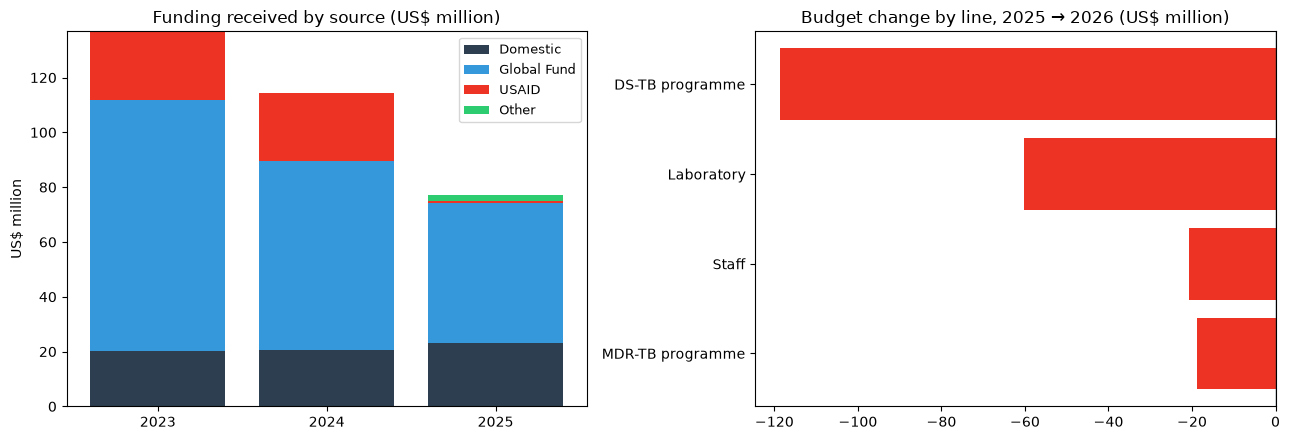

In [35]:
f = nga(fund).set_index("year").loc[[2023, 2024, 2025]]
src = {"rcvd_tot_domestic": "Domestic", "rcvd_tot_gf": "Global Fund",
       "rcvd_tot_usaid": "USAID", "rcvd_tot_grnt": "Other"}
colors = ["#2C3E50", "#3498DB", "#ED3324", "#2ECC71"]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
bottom = np.zeros(len(f))
for (col, label), c in zip(src.items(), colors):
    vals = f[col].values / 1e6
    axes[0].bar(f.index.astype(str), vals, bottom=bottom, label=label, color=c)
    bottom += vals
axes[0].set_title("Funding received by source (US$ million)")
axes[0].set_ylabel("US$ million"); axes[0].legend(fontsize=9)

labels = {"budget_lab": "Laboratory", "budget_staff": "Staff",
          "budget_prog": "DS-TB programme", "budget_mdrmgt": "MDR-TB programme"}
b = nga(bud).set_index("year")
diff = ((b.loc[2026, list(labels)] - b.loc[2025, list(labels)]) / 1e6).sort_values(ascending=False)
axes[1].barh([labels[c] for c in diff.index], diff.values, color="#ED3324")
axes[1].axvline(0, color="#2C3E50", lw=1)
axes[1].set_title("Budget change by line, 2025 → 2026 (US$ million)")
plt.tight_layout(); plt.show()

**The story in three sentences:**

1. In 2025, USAID funding to Nigeria's TB programme collapsed by **97%** and total funding received fell by a third — the Global Fund is now the dominant funder (Q4, Q5).
2. The 2026 plan responded by **halving** the national TB budget, with the core drug-susceptible TB programme line cut by **87%** (Q6, Q7).
3. Yet notifications kept rising to a record **455,258** and treatment coverage reached **88%** (Q2, and the glance table) — while testing volume fell **17%** (Q8). The system is running hotter on less fuel.

**⚖️ Analyst's humility:** these data show *what* happened, side by side — they don't prove *why*. Funding cuts and falling test volumes are consistent with each other, but proving causation needs more evidence. Good analysts narrate the pattern and flag the open questions. That's what you just did.

---
## 🚀 Bonus challenges — no scaffolding now

Same patterns, new questions. Columns are pointed out; the thinking is yours. Answers (with working) are at the end of the [solutions notebook](TB_starter_solutions.ipynb).

| # | Challenge | Where to look |
|---|-----------|---------------|
| B1 | In which year did treatment coverage (`c_cdr`) first reach **50% or more**? | `nga_est`, filter + `.min()` on years |
| B2 | How did **under-5 household contacts started on preventive treatment** change, 2024 → 2025? | `TB_contact_tpt…`, column `newinc_con04_prevtx` |
| B3 | Since 2015, in which year did notifications grow **fastest in % terms**? | `noti`, `c_newinc`, `.pct_change()` + `idxmax()` |
| B4 | Which **age–sex group** had the most notified cases in 2025? | `noti`, columns like `newrel_m3544` (m/f + age band), `idxmax()` |
| B5 | For 2025, how much **less was received than the budget said was needed**? | `fund.rcvd_tot` vs `bud.budget_tot` — cross-file subtraction |

In [36]:
# B2's file, ready for you:
tpt = pd.read_csv("data/TB_contact_tpt_2026-08-25.csv")
nga(tpt)[["year", "newinc_con04_prevtx"]].tail(3)

,year,newinc_con04_prevtx
1537,2023,83955.0
1538,2024,95632.0
1539,2025,29809.0


In [37]:
# B1 — first year treatment coverage reached 50%+
cov = nga_est.set_index("year")["c_cdr"]
first50 = cov[cov >= 50].index.min()
print(f"B1: treatment coverage first hit 50%+ in {first50} ({cov[first50]:.0f}%)")

# B2 — under-5 household contacts started on preventive treatment
u5 = nga(tpt).set_index("year")["newinc_con04_prevtx"]
print(f"B2: {u5[2024]:,.0f} (2024) -> {u5[2025]:,.0f} (2025) ({100*(u5[2025]-u5[2024])/u5[2024]:+.1f}%)")

# B3 — fastest notification growth since 2015
cn = nga(noti).set_index("year")["c_newinc"].sort_index()
growth = cn.pct_change().loc[2016:2025] * 100
print(f"B3: fastest growth in {growth.idxmax()} ({growth.max():+.1f}%)")

# B4 — age-sex group with most notifications in 2025
bands = [f"newrel_{s}{a}" for s in "mf" for a in
         ["04", "514", "1524", "2534", "3544", "4554", "5564", "65"]]
r = nga(noti).set_index("year").loc[2025, bands]
print(f"B4: {r.idxmax()} with {r.max():,.0f} cases  (m = male, f = female; 3544 = ages 35-44)")

# B5 — received vs required, 2025
needed = nga(bud).set_index("year").loc[2025, "budget_tot"]
received = nga(fund).set_index("year").loc[2025, "rcvd_tot"]
print(f"B5: needed ${needed:,.0f}, received ${received:,.0f} -> gap ${needed-received:,.0f} ({100*received/needed:.1f}% funded)")

B1: treatment coverage first hit 50%+ in 2022 (58%)
B2: 95,632 (2024) -> 29,809 (2025) (-68.8%)
B3: fastest growth in 2021 (+50.8%)
B4: newrel_m3544 with 55,151 cases  (m = male, f = female; 3544 = ages 35-44)
B5: needed $405,120,000, received $77,092,704 -> gap $328,027,296 (19.0% funded)


---
## 🎓 What you just learned

| Skill | Where you used it |
|-------|-------------------|
| Downloading open data with `wget` + raw GitHub URLs | Step 1 |
| Reading a data dictionary; decoding column prefixes | Step 2, Q7, Q8 |
| Filtering with boolean masks (`&`, comparisons) | everywhere |
| `nunique` vs `count` | Q1 |
| Sorting, ranking, zero-based indexes | Q2 |
| Shares: part ÷ whole | Q3 |
| Percentage change and its base-year trap | Q4, Q6, Q8 |
| `idxmax` / `idxmin` vs `max` / `min` | Q5, Q7, Q9 |
| Missing data: NaN ≠ 0; adapt the question honestly | Q9 |
| Data-quality detective work | Q10 |

That is a genuine first course in data analysis — on data that was published **this month**, with a real error you found yourself.

## ⭐ Like this? Help the next learner find it

1. **Star the repo** → [github.com/thegoodworks/dataworks-tb](https://github.com/thegoodworks/dataworks-tb) — stars are how other beginners discover free lessons like this.
2. **Follow [@thegoodworks](https://github.com/thegoodworks)** → Vol. 02 is coming, and your follow tells us what to build.
3. **Share your checklist** — post your answers or your own question as an [issue](https://github.com/thegoodworks/dataworks-tb/issues), or tag us. Teaching someone else is the fastest way to cement what you learned.
4. **Make it yours** — swap `"Nigeria"` for your own country in the `nga()` helper and re-run everything. Same code, new story. (Then rename the helper. 😄)

## 🙏 Data attribution & licence

> Data: **World Health Organization**, *WHO Global Tuberculosis Report 2026* database (`gtb_database`, snapshot 2026-08-25), accessed 17 November 2026 via [GTB-TME/gtbreport2026](https://github.com/GTB-TME/gtbreport2026). We acknowledge the **national TB programmes and other national authorities** that provided the underlying data. Used under the [WHO data policy](https://www.who.int/about/policies/publishing/data-policy) and its [terms and conditions](https://www.who.int/about/policies/publishing/data-policy/terms-and-conditions) for public-health purposes.
>
> Notebook & code: MIT © [thegoodworks.ng](https://www.thegoodworks.ng) (**dataworks**). This is an independent educational project — **not affiliated with or endorsed by WHO**.